# 03 - Embryo Bulk Composition with Sulfur (~5 Myr)

This notebook traces N-body collision histories through the gas-disk stage, assigns each surviving particle a mixture of EF/EC/OC/CI meteorite inputs, and computes its primordial Fe–Ni–Si–O–S differentiation.

`S` is total bulk sulfur on the composition scale used for mixing. `S_sil` and `S_met` are the resulting silicate and metal phase amounts; they sum to `S`. The first differentiation event uses the Rose-Weston sulfur model.

**Input:** `notebooks/work_flow_S/Tables/Meteorites_composition.csv` from `A_01_meteorite_bulk_composition_s.ipynb`. **Output:** `notebooks/work_flow_S/Tables/03_embryo_bulk_composition.csv`.

Run from the project root or `notebooks/work_flow_S`; the N-body data path remains relative to `notebooks/work_flow_S`.

**Mass-to-mole hand-off:** Collision ancestry supplies source masses in Earth-mass units. Source-mass fractions weight the A_01 inventories (mol per 100 g complete body), not separately normalized source mole fractions. The sulfur solver redistributes those moles between phases; the unmodeled mass fraction is carried without chemical repartitioning.


In [1]:
# Primordial embryo composition, at the gas-disk end snapshot.
PROJECT_ROOT = None
WORKFLOW_DIR = None
MODEL_ID = 'simF_01'
MODEL_DIR = None                # None = PROJECT_ROOT/notebooks/N_body_dataset/MODEL_ID
GAS_TIME = '5.0 Myr'           # Snapshot label
INITIAL_TIME = '0.0 Myr'       # Initial composition snapshot
EF_MAX_AU = 0.9747
EC_MAX_AU = 1.0674
OC_MAX_AU = 3.0
CI_MIN_AU = 2.0            # Existing selection precedence assigns 2–3 au to OC
METEORITE_FILE = None           # A_01 MgO ratio table, for CI plots only
METEORITE_INVENTORY_FILE = None # A_01 mol per 100 g complete-body table
METEORITE_COVERAGE_FILE = None  # A_01 mass coverage table
EMBRYO_DISPLAY_THRESHOLD = 0.05  # M Earth; plot only, not the exported embryo inventory
OUTPUT_FILE = None


In [2]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import os
import sys
import matplotlib.patches as mpatches
from pathlib import Path
working_dir = Path.cwd()
project_root = (Path(PROJECT_ROOT).expanduser().resolve() if PROJECT_ROOT is not None
                else next((p for p in (working_dir, *working_dir.parents)
                           if (p / "src" / "accrediff").is_dir()), None))
if project_root is None:
    raise RuntimeError("Could not locate the AccreDiff repository root.")
workflow_dir = (Path(WORKFLOW_DIR).expanduser().resolve() if WORKFLOW_DIR is not None
                else project_root / 'kong_2027_backup' / 'work_flow_S')
sys.path.insert(0, str(project_root / 'src'))
import accrediff as ad

# ── Plot style ──────────────────────────────────────────
plt.rcParams.update({
    "font.family": "serif",
    "font.size": 12,
    "axes.linewidth": 1,
    "axes.labelsize": 14,
    "xtick.labelsize": 12,
    "ytick.labelsize": 12,
    "xtick.direction": "in",
    "ytick.direction": "in",
    "xtick.top": False,
    "ytick.right": False,
    "figure.dpi": 150,
})

Colors = {
    'Earth'  : "#1f77b4",
    'Mars'   : "#d62728",
    'EF'     : "#8c564b",
    'EC'     : "#ff7f0e",
    'OC'     : "#2ca02c",
    'CI'     : "#9467bd",
}

print("Setup complete.")

Setup complete.


## 1. Load N-body Simulation Data

Read all `aei` snapshot files from the selected model directory.  
Each snapshot contains orbital elements and masses for all particles at a given time step (0.1 Myr interval).

- Mass is converted from solar units to Earth mass units (`m_e = m / ME`)
- Particle index `i` is used as the DataFrame index for cross-snapshot tracking

In [3]:
# ── Model selection ──────────────────────────────────────
model = MODEL_ID
from pathlib import Path
data_dir = Path(MODEL_DIR) if MODEL_DIR is not None else project_root / 'notebooks' / 'N_body_dataset' / model
Path = str(data_dir)

# ── Load all aei snapshots ───────────────────────────────
file_paths = sorted(
    [os.path.join(Path, f) for f in os.listdir(Path) if f.startswith('aei')]
)
keys = [f'{i/10:.1f} Myr' for i in range(len(file_paths))]

col_names = ['t', 'i', 'a', 'e', 'inc', 'Omega', 'w', 'T', 'E', 'M', 'm', 'r']
A_dict = {}
for path, key in zip(file_paths, keys):
    A_dict[key] = pd.read_csv(
        path, sep=' ', header=None, names=col_names, index_col='i'
    )

# Convert mass to Earth units
for key in A_dict:
    A_dict[key]['m_e'] = A_dict[key]['m'] / ad.constants.ME
    A_dict[key]['N']   = len(A_dict[key])

print(f"Model   : {model}")
print(f"Snapshots loaded: {len(A_dict)}")
print(f"Time range: {list(A_dict.keys())[0]} → {list(A_dict.keys())[-1]}")

Model   : simF_01
Snapshots loaded: 2001
Time range: 0.0 Myr → 200.0 Myr


## 2. Initial Composition Classification (t = 0 Myr)

Particles are assigned a meteorite composition type based on their initial semi-major axis:

| Semi-major axis (AU) | Composition type |
|---------------------|-----------------|
| a ≤ 1.0             | EF              |
| 1.0 < a ≤ 1.3       | EC              |
| 1.3 < a ≤ 3.0       | OC              |
| a > 3.0             | CI              |

The two outermost giant planets (index 0 and 1) are excluded.

In [4]:
time_zero = INITIAL_TIME
df_com = A_dict[time_zero][['a', 'e', 'inc', 'm_e']].iloc[2:]  # remove giant planets

conditions = [
    (df_com['a'] <= EF_MAX_AU),
    (df_com['a'] > EF_MAX_AU) & (df_com['a'] <= EC_MAX_AU),
    (df_com['a'] > EC_MAX_AU) & (df_com['a'] <= OC_MAX_AU),
    (df_com['a'] > CI_MIN_AU),
]
choices = ['EF', 'EC', 'OC', 'CI']
df_com['com'] = np.select(conditions, choices, default=None)
i_com_mapping = dict(zip(df_com.index, df_com['com']))

# Summary
for c in choices:
    n = (df_com['com'] == c).sum()
    print(f"  {c}: {n} particles")
print(f"  Total: {len(df_com)} particles")

  EF: 796 particles
  EC: 699 particles
  OC: 1093 particles
  CI: 212 particles
  Total: 2800 particles


## 3. Visualize Initial Particle Distribution

Scatter plot of eccentricity vs. semi-major axis at t = 0 Myr, colored by composition type.  
A KDE curve (gray) shows the radial surface density profile.

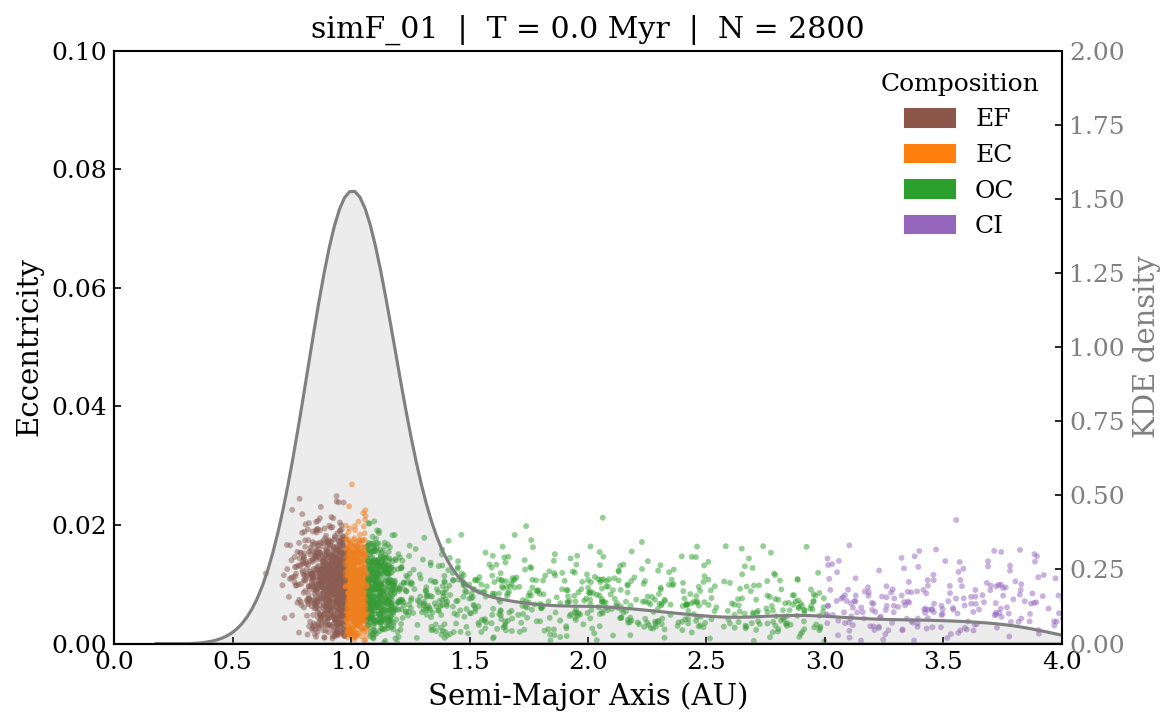

In [5]:
color_map = {c: Colors[c] for c in choices}
colors     = df_com['com'].map(color_map)

fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(df_com['a'], df_com['e'], c=colors, s=8, alpha=0.5, edgecolors='none')
ax.set_xlim(0, 4)
ax.set_ylim(0, 0.1)
ax.set_xlabel('Semi-Major Axis (AU)')
ax.set_ylabel('Eccentricity')
ax.set_title(f'{model}  |  T = {time_zero}  |  N = {len(df_com)}')
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

legend_handles = [mpatches.Patch(color=color_map[k], label=k) for k in choices]
ax.legend(handles=legend_handles, title='Composition', loc='upper right', frameon=False)

# KDE overlay
ax2 = ax.twinx()
sns.kdeplot(df_com['a'], ax=ax2, color='gray', linewidth=1.5, fill=True, alpha=0.15)
ax2.set_ylim(0, 2)
ax2.set_ylabel('KDE density', color='gray')
ax2.tick_params(axis='y', labelcolor='gray')

plt.tight_layout()
plt.show()

## 4. Load Collision Records & Filter Gas-Disk Phase

Collision events are read from the `Collision` file in the model directory.  
Only collisions occurring **within the gas disk lifetime** (t ≤ 5 Myr) are retained.

In [6]:
# ── Locate collision file ────────────────────────────────
collision_files = [
    os.path.join(Path, f) for f in os.listdir(Path) if f.startswith('Collision')
]
if not collision_files:
    raise FileNotFoundError(f"No Collision file found in {Path}")

col_names_c = [
    'time',
    'indexi', 'mi', 'ri', 'xi', 'yi', 'zi', 'vxi', 'vyi', 'vzi', 'Sxi', 'Syi', 'Szi',
    'indexj', 'mj', 'rj', 'xj', 'yj', 'zj', 'vxj', 'vyj', 'vzj', 'Sxj', 'Syj', 'Szj',
]

C_data = pd.read_csv(collision_files[0], sep=r'\s+', header=None, names=col_names_c)
C_data['m_ei'] = C_data['mi'] / ad.constants.ME
C_data['m_ej'] = C_data['mj'] / ad.constants.ME

# Filter: gas disk phase only
gas_time   = GAS_TIME
gas_time_yr = A_dict[gas_time]['t'].iloc[0]
C_withgas  = C_data[C_data['time'] <= gas_time_yr].copy()

print(f"Gas disk lifetime : {gas_time_yr:.0f} yr")
print(f"Total collisions  : {len(C_data)}")
print(f"Within gas disk   : {len(C_withgas)}")

Gas disk lifetime : 4928131 yr
Total collisions  : 2482
Within gas disk   : 2022


## 5. Classify Particles at t = 5 Myr

Particles surviving to the end of the gas disk phase are split into two groups:

- **Non-collided** (`df_gas_original`): retain their original `t = 0` composition
- **Collided** (`df_gas_collision`): composition must be reconstructed from collision history

In [7]:
df_gas = A_dict[gas_time][['a', 'e', 'inc', 'm_e']].iloc[2:].copy()

gas_index_set      = set(df_gas.index)
collision_id_set   = set(C_withgas['indexi']) | set(C_withgas['indexj'])
intersection_list  = list(gas_index_set & collision_id_set)
original_list      = list(gas_index_set - collision_id_set)

# Initialize composition columns
for col in choices:
    df_gas[col] = np.nan

df_gas_collision = df_gas.loc[intersection_list].copy()
df_gas_original  = df_gas.loc[original_list].copy()

print(f"Particles at {gas_time}    : {len(df_gas)}")
print(f"  Non-collided             : {len(df_gas_original)}")
print(f"  Collided (need tracing)  : {len(df_gas_collision)}")

Particles at 5.0 Myr    : 678
  Non-collided             : 528
  Collided (need tracing)  : 150


## 6. Assign Compositions

### 6a. Non-collided Particles
Directly inherit the composition type from `t = 0` classification.

### 6b. Collided Particles — Collision History Tracing
`CollisionTracer.trace_full_history()` reconstructs the full merger tree for each particle,
returning all ancestor particle indices. The mass of each ancestor is then summed by
composition category to obtain the mixed bulk composition.

In [8]:
# ── 6a: Non-collided ─────────────────────────────────────
for idx in df_gas_original.index:
    com_type = i_com_mapping.get(idx)
    if com_type in choices:
        df_gas_original.at[idx, com_type] = df_com.loc[idx, 'm_e']

# ── 6b: Collided — trace full merger history ──────────────
df_c   = C_withgas[['time', 'indexi', 'm_ei', 'indexj', 'm_ej']].copy()
tracer = ad.CollisionTracer(df_c)

for idx in df_gas_collision.index:
    h           = tracer.trace_full_history(idx)
    index_union = list(set(h['indexi']) | set(h['indexj']))

    union_data = [
        {
            'Index'   : i,
            'Category': i_com_mapping.get(i),
            'm_e'     : df_com.loc[i, 'm_e'] if i in df_com.index else None,
        }
        for i in index_union
    ]
    union_df      = pd.DataFrame(union_data)
    category_sums = union_df.groupby('Category')['m_e'].sum()

    for com_type in choices:
        if com_type in category_sums.index:
            df_gas_collision.at[idx, com_type] = category_sums[com_type]

print("Composition assignment complete.")

Composition assignment complete.


## 7. Merge, Compute Mixing Ratios & Thermodynamic Conditions

All particles are merged into `df_gas_all`.  
For each particle:
- Meteorite mass fractions (`EF_ratio`, `EC_ratio`, `OC_ratio`, `CI_ratio`) are calculated
- Formation pressure `P` is estimated from mass via `ad.Early_pressure()`
- Formation temperature `T` is derived from `P` via `ad.P_to_T()`

In [9]:
df_gas_all = (
    pd.concat([df_gas_collision, df_gas_original])
    .sort_values('m_e')
    .reset_index()
)

# Fill NaN → 0 and compute mass fractions
for col in choices:
    df_gas_all[col] = df_gas_all[col].fillna(0)

# Trace each gas-disk particle back to its initial N-body source masses.
# N-body mass, rather than mole fraction, determines how much of each
# endmember contributes. Numerical collision-output rounding is audited.
total = df_gas_all[choices].sum(axis=1)
df_gas_all['source_mass_relative_error'] = (
    (total - df_gas_all['m_e']) / df_gas_all['m_e']
)
if (total <= 0).any() or (df_gas_all['source_mass_relative_error'].abs() > 1e-5).any():
    bad = df_gas_all.loc[
        (total <= 0) | (df_gas_all['source_mass_relative_error'].abs() > 1e-5),
        ['i', 'm_e', 'source_mass_relative_error']
    ]
    raise ValueError(f'Initial source masses do not close to N-body particle mass:\n{bad.head()}')
# Divide by traced mass after the discrepancy check; this avoids a small
# artificial mass deficit caused solely by N-body output rounding.
for col in choices:
    df_gas_all[f'{col}_ratio'] = df_gas_all[col] / total

# Thermodynamic conditions
df_gas_all['P'] = ad.Early_pressure(df_gas_all['m_e'])
df_gas_all['T'] = df_gas_all['P'].apply(ad.P_to_T)

print(f"Total particles in df_gas_all: {len(df_gas_all)}")
df_gas_all.head()

Total particles in df_gas_all: 678


,i,a,e,inc,m_e,EF,EC,OC,CI,source_mass_relative_error,EF_ratio,EC_ratio,OC_ratio,CI_ratio,P,T
0,2662,3.920178,0.069384,0.035070,0.000355,0.000000,0.0,0.000000,0.000355,0.0,0.0,0.0,0.0,1.0,0.409734,1896.420794
1,1390,1.073608,0.109201,0.020373,0.000359,0.000359,0.0,0.000000,0.000000,0.0,1.0,0.0,0.0,0.0,0.410254,1896.448871
2,2300,3.000788,0.052617,0.035121,0.000384,0.000000,0.0,0.000000,0.000384,0.0,0.0,0.0,0.0,1.0,0.412977,1896.595910
3,2771,2.438209,0.335377,0.020906,0.000442,0.000000,0.0,0.000442,0.000000,0.0,0.0,0.0,1.0,0.0,0.419495,1896.947826
4,2427,2.490507,0.246477,0.008544,0.000450,0.000000,0.0,0.000450,0.000000,0.0,0.0,0.0,1.0,0.0,0.420406,1896.997035


## 8. Assign Geochemical Bulk Compositions with Sulfur

A_01 provides separate MgO-normalized display ratios, molar inventories per 100 g of complete source body, and modeled/unmodeled mass coverage. N-body source mass fractions weight the inventories directly; each endmember must not be normalized to unit total moles. `EarlyComUpdater_S` computes primordial metal–silicate equilibrium on this common mass basis. Unmodeled mass remains outside the chemical solver and is carried separately.


In [10]:
# The sulfur updater is provided by accrediff.differentiation_sulfur
# and exported as ad.EarlyComUpdater_S.


In [11]:
from pathlib import Path

# Resolve the meteorite table within this sulfur workflow.
Mete_file = Path(METEORITE_FILE) if METEORITE_FILE is not None else workflow_dir / 'Tables' / 'Meteorites_composition.csv'
df_Mete = pd.read_csv(Mete_file, index_col=0)
inventory_file = (Path(METEORITE_INVENTORY_FILE) if METEORITE_INVENTORY_FILE is not None
                  else workflow_dir / 'Tables' / 'Meteorites_inventory_per_100g.csv')
coverage_file = (Path(METEORITE_COVERAGE_FILE) if METEORITE_COVERAGE_FILE is not None
                 else workflow_dir / 'Tables' / 'Meteorites_mass_coverage.csv')
df_inventory = pd.read_csv(inventory_file, index_col=0)
source_coverage = pd.read_csv(coverage_file, index_col=0)
if list(df_inventory.columns) != choices or list(df_inventory.index) != list(df_Mete.index):
    raise ValueError('A_01 molar inventory and MgO display table have incompatible axes.')
if set(source_coverage.index) != set(choices):
    raise ValueError('A_01 mass coverage lacks an endmember.')

mantle_items = ['MgO', 'Al2O3', 'CaO', 'FeO', 'NiO', 'SiO2']
core_items = ['Fe', 'Ni', 'Si', 'O']
major_items = mantle_items + core_items + ['S']
phase_sulfur_items = ['S_sil', 'S_met']
assert set(major_items) <= set(df_Mete.index), 'Meteorite table must include total S.'
assert list(df_Mete.columns) == choices

# Values are mol per 100 g COMPLETE source body. Do not divide each
# source by its own total moles: mass weights would then lose their basis.
dict_Mete = df_inventory.to_dict()
weights = df_gas_all[[f'{kind}_ratio' for kind in choices]].to_numpy(dtype=float)
df_gas_all['untracked_mass_fraction'] = (
    weights @ source_coverage.loc[choices, 'untracked_mass_fraction'].to_numpy(dtype=float)
)

for col in major_items + phase_sulfur_items:
    df_gas_all[col] = np.nan

updater = ad.EarlyComUpdater_S(df_gas_all, dict_Mete, major_items)
early_results = updater.batch_update()

assert np.allclose(df_gas_all['S_sil'] + df_gas_all['S_met'], df_gas_all['S'], atol=1e-10)
# The equilibrium solver redistributes the modeled elements; it cannot
# create or remove the unmodeled mass. Include both S phases only once.
mass_calc = ad.MolarMassCalculator()
phase_masses = {name: mass_calc.molar_mass(name) for name in mantle_items + core_items}
df_gas_all['tracked_mass_fraction'] = (
    sum(df_gas_all[name] * molar_mass for name, molar_mass in phase_masses.items())
    + df_gas_all['S_sil'] * mass_calc.molar_mass('S')
    + df_gas_all['S_met'] * mass_calc.molar_mass('S')
) / 100.0
if not np.allclose(
    df_gas_all['tracked_mass_fraction'] + df_gas_all['untracked_mass_fraction'],
    1.0, rtol=0.0, atol=1e-7,
):
    raise RuntimeError('Initial differentiation changed complete-body mass coverage.')
print(f'Primordial sulfur differentiation complete: {len(early_results)} particles')
df_gas_all[major_items + phase_sulfur_items].describe()


Primordial sulfur differentiation complete: 678 particles


,MgO,Al2O3,CaO,FeO,NiO,SiO2,Fe,Ni,Si,O,S,S_sil,S_met
count,678.000000,678.000000,678.000000,678.000000,678.000000,678.000000,678.000000,678.000000,6.780000e+02,678.000000,678.000000,678.000000,678.000000
mean,0.568023,0.021605,0.031840,0.245645,0.005092,0.580042,0.160564,0.016954,5.250475e-03,0.009829,0.155119,0.001255,0.153864
std,0.059839,0.004305,0.006289,0.100044,0.005300,0.095923,0.146512,0.007317,1.540460e-02,0.014559,0.088370,0.000563,0.087883
min,0.423145,0.016779,0.024500,0.001933,0.000001,0.313285,0.044565,0.001632,3.452402e-08,0.000053,0.000000,0.000000,0.000000
25%,0.590074,0.021287,0.031576,0.285703,0.003733,0.627326,0.106372,0.017342,7.997927e-07,0.004796,0.138154,0.001329,0.136797
50%,0.590074,0.021287,0.031576,0.285808,0.003744,0.627326,0.106397,0.017369,8.075812e-07,0.004812,0.138154,0.001335,0.136819
75%,0.590074,0.021287,0.031576,0.285832,0.003771,0.627326,0.106502,0.017380,8.416979e-07,0.004852,0.138154,0.001349,0.136825
max,0.650094,0.038667,0.056461,0.312493,0.017833,0.667854,0.546632,0.029905,6.522682e-02,0.046754,0.359335,0.002182,0.357215


## 9. Filter Embryos (m ≥ 0.05 M⊕)

Planetary embryos are defined as particles with mass ≥ 0.05 Earth masses.  
They are sorted by mass (descending) and assigned sequential IDs (`Embryo 1`, `Embryo 2`, ...).  
Colors skip indices 0 (blue) and 3 (red) from `tab10`, which are reserved for Earth and Mars.

In [12]:
df_embryos = (
    df_gas_all[df_gas_all['m_e'] >= EMBRYO_DISPLAY_THRESHOLD]
    .sort_values('m_e', ascending=False)
    .reset_index(drop=True)
)
embryos_id = [f'Embryo {i+1}' for i in range(len(df_embryos))]

# Assign colors (skip blue=0 and red=3 reserved for Earth/Mars)
cmap          = plt.get_cmap('tab10')
color_indices = [i for i in range(10) if i not in (0, 3)]
embryo_colors = [cmap(color_indices[i % len(color_indices)]) for i in range(len(df_embryos))]

print(f"Number of embryos (m ≥ 0.05 M⊕): {len(df_embryos)}")
df_embryos[['m_e', 'a', 'P', 'T'] + choices]

Number of embryos (m ≥ 0.05 M⊕): 8


,m_e,a,P,T,EF,EC,OC,CI
0,0.289050,0.899196,32.760975,2773.041350,0.112718,0.099489,0.076418,0.000426
1,0.231144,0.991757,26.272018,2527.443514,0.088494,0.087603,0.055048,0.000000
2,0.185474,1.070045,21.154238,2450.630900,0.076179,0.060915,0.048380,0.000000
3,0.176045,0.833015,20.097598,2441.871877,0.083532,0.044579,0.047934,0.000000
4,0.159168,1.159684,18.206422,2422.892127,0.042473,0.058654,0.058042,0.000000
5,0.128717,0.766440,14.793984,2375.701039,0.058982,0.042980,0.026755,0.000000
6,0.081188,0.685950,9.467981,2259.212534,0.049836,0.018877,0.012476,0.000000
7,0.074662,1.348028,8.736662,2238.330700,0.016439,0.026370,0.030983,0.000871


## 10. CI-Normalized Spider Diagram

Embryo compositions are normalized to both **Mg** and **CI chondrites**:

$$\left(\frac{X}{\text{Mg}}\right)_{\text{CI}} = \frac{(X/\text{MgO})_{\text{embryo}}}{(X/\text{MgO})_{\text{CI}}}$$

- **Mantle** components (Al, Ca, Fe, Ni, Si, S): square markers (`s`); sulfur uses `S_sil`
- **Core** components (Fe, Ni, Si, S): circle markers (`o`); sulfur uses `S_met`
- Both sulfur phases use the bulk CI `S/MgO` value as their common reference, so their sum represents CI-normalized total sulfur
- Marker size scales with embryo mass

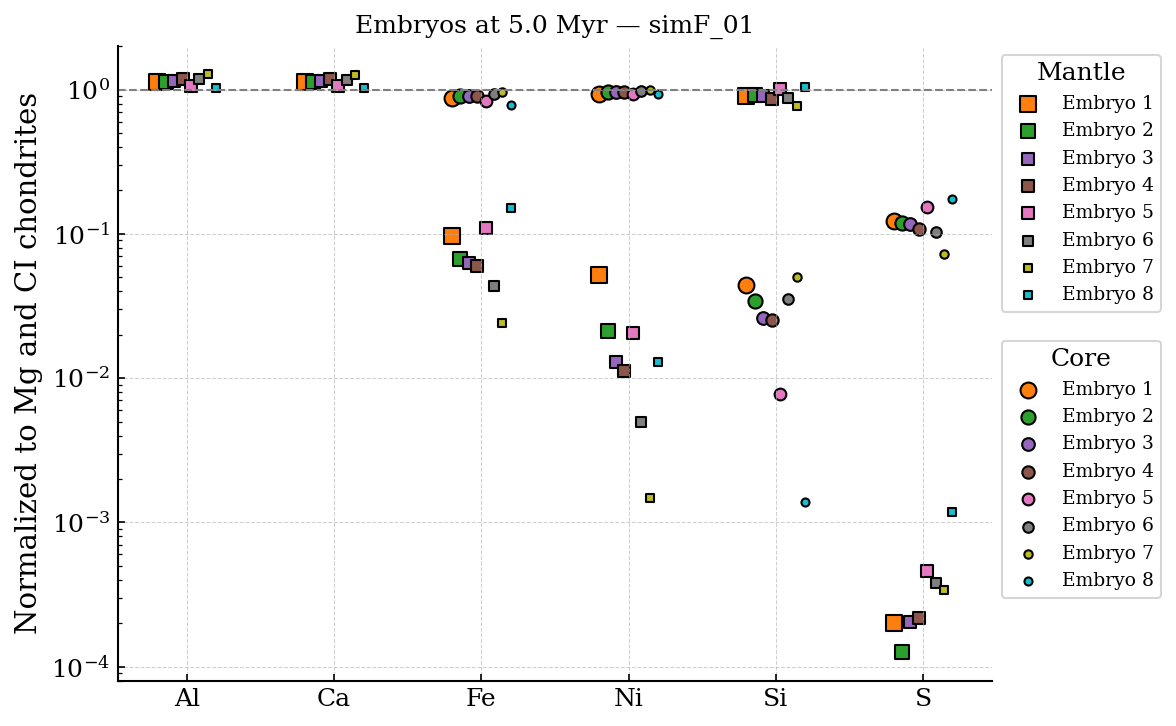

In [13]:
# ── Normalize to MgO ─────────────────────────────────────
# Include phase-resolved sulfur so both silicate and metal sulfur can be shown.
normalization_items = major_items + phase_sulfur_items
df_embryos_Mg = df_embryos[normalization_items].div(df_embryos['MgO'].values, axis=0)

# ── Normalize to CI ───────────────────────────────────────
CI_bulk_mg = ad.constants.CI_bulk_mg
df_CI      = pd.DataFrame([CI_bulk_mg])

mantle_keys = mantle_items[1:]          # Al2O3, CaO, FeO, NiO, SiO2
core_keys   = core_items[:-1]           # Fe, Ni, Si
ci_core_ref = mantle_items[3:]          # FeO, NiO, SiO2 as CI reference for core

# S_sil and S_met are complementary portions of bulk S. Use the same bulk-CI
# S/MgO reference for both phases, rather than treating either phase as total S.
ci_sulfur_ref = float(df_Mete.loc['S', 'CI'])
if not np.isfinite(ci_sulfur_ref) or ci_sulfur_ref <= 0:
    raise ValueError('The CI meteorite composition must contain positive S/MgO.')

df_embryos_CI = df_embryos_Mg[mantle_keys + core_keys + phase_sulfur_items].copy()
df_embryos_CI[mantle_keys] = df_embryos_CI[mantle_keys].div(df_CI[mantle_keys].values[0])
df_embryos_CI[core_keys]   = df_embryos_CI[core_keys].div(df_CI[ci_core_ref].values[0])
df_embryos_CI[phase_sulfur_items] = (
    df_embryos_CI[phase_sulfur_items] / ci_sulfur_ref
)

# ── Plot ──────────────────────────────────────────────────
elements         = ['Al', 'Ca', 'Fe', 'Ni', 'Si', 'S']
x_idx            = np.arange(len(elements))
core_x_idx       = np.array([2, 3, 4, 5])
mantle_plot_keys = mantle_keys + ['S_sil']
core_plot_keys   = core_keys + ['S_met']
offsets          = np.linspace(-0.2, 0.2, len(df_embryos_CI))

fig, ax = plt.subplots(figsize=(8, 5))
legend_groups = {'Mantle': [], 'Core': []}

for i in range(len(df_embryos_CI)):
    s = 200 * df_embryos['m_e'].iloc[i]
    c = embryo_colors[i]

    sc_m = ax.scatter(x_idx + offsets[i],
                      df_embryos_CI[mantle_plot_keys].iloc[i].values,
                      marker='s', s=s, color=c, edgecolor='k',
                      label=f'{embryos_id[i]} mantle')
    sc_c = ax.scatter(core_x_idx + offsets[i],
                      df_embryos_CI[core_plot_keys].iloc[i].values,
                      marker='o', s=s, color=c, edgecolor='k',
                      label=f'{embryos_id[i]} core')
    legend_groups['Mantle'].append(sc_m)
    legend_groups['Core'].append(sc_c)

ax.set_yscale('log')
ax.set_xticks(x_idx)
ax.set_xticklabels(elements)
ax.set_ylabel('Normalized to Mg and CI chondrites')
ax.axhline(1.0, color='gray', linestyle='--', linewidth=1)
ax.grid(True, which='major', ls='--', lw=0.5, alpha=0.6)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.set_title(f'Embryos at {gas_time} — {model}', fontsize=12)

leg1 = ax.legend(legend_groups['Mantle'], embryos_id, title='Mantle',
                 bbox_to_anchor=(1.0, 1.0), loc='upper left', fontsize=9)
ax.add_artist(leg1)
ax.legend(legend_groups['Core'], embryos_id, title='Core',
          bbox_to_anchor=(1.0, 0.55), loc='upper left', fontsize=9)

plt.tight_layout()
plt.show()


## 11. Export Results

Save all particles at ~5 Myr. The geochemical columns include total sulfur `S` and its two phase amounts `S_sil` and `S_met`; the latter sum to `S`. The total `S` column is retained for auditing, while later event mixing should use `S_sil` and `S_met` so sulfur is not counted twice.


In [14]:
df_gas_all

,i,a,e,inc,m_e,EF,EC,OC,CI,source_mass_relative_error,...,NiO,SiO2,Fe,Ni,Si,O,S,S_sil,S_met,tracked_mass_fraction
0,2662,3.920178,0.069384,0.035070,0.000355,0.000000,0.000000,0.000000,0.000355,0.000000e+00,...,0.017833,0.410617,0.044565,0.001632,3.452402e-08,0.046197,0.359335,0.002120,0.357215,0.834368
1,1390,1.073608,0.109201,0.020373,0.000359,0.000359,0.000000,0.000000,0.000000,0.000000e+00,...,0.000001,0.313317,0.546632,0.029905,6.519412e-02,0.000053,0.000000,0.000000,0.000000,0.863877
2,2300,3.000788,0.052617,0.035121,0.000384,0.000000,0.000000,0.000000,0.000384,0.000000e+00,...,0.017833,0.410617,0.044579,0.001632,3.459755e-08,0.046211,0.359335,0.002121,0.357214,0.834368
3,2771,2.438209,0.335377,0.020906,0.000442,0.000000,0.000000,0.000442,0.000000,0.000000e+00,...,0.003722,0.627326,0.106340,0.017392,7.895767e-07,0.004780,0.138154,0.001323,0.136832,0.976958
4,2427,2.490507,0.246477,0.008544,0.000450,0.000000,0.000000,0.000450,0.000000,0.000000e+00,...,0.003722,0.627326,0.106341,0.017391,7.899320e-07,0.004780,0.138154,0.001323,0.136831,0.976958
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
673,1918,1.159684,0.014635,0.002387,0.159168,0.042473,0.058654,0.058042,0.000000,3.765824e-07,...,0.000566,0.580904,0.418965,0.025622,4.453663e-03,0.004431,0.077716,0.000232,0.077484,0.950203
674,316,0.833015,0.016087,0.002703,0.176045,0.083532,0.044579,0.047934,0.000000,-2.837346e-07,...,0.000314,0.511071,0.463004,0.026846,1.497851e-02,0.002852,0.056402,0.000113,0.056289,0.925652
675,1723,1.070045,0.027867,0.010294,0.185474,0.076179,0.060915,0.048380,0.000000,-2.154480e-07,...,0.000359,0.531557,0.460373,0.026797,1.534386e-02,0.003041,0.060401,0.000105,0.060297,0.933561
676,678,0.991757,0.010479,0.004067,0.231144,0.088494,0.087603,0.055048,0.000000,-4.033850e-07,...,0.000582,0.537206,0.459542,0.026703,1.998246e-02,0.004011,0.061018,0.000065,0.060953,0.937182


In [15]:
save_dir = workflow_dir / 'Tables'
save_dir.mkdir(parents=True, exist_ok=True)
save_file = Path(OUTPUT_FILE) if OUTPUT_FILE is not None else save_dir / '03_embryo_bulk_composition.csv'
df_gas_all.to_csv(save_file, index=True)

exported = pd.read_csv(save_file, index_col=0)
assert set(major_items + phase_sulfur_items + [
    'tracked_mass_fraction', 'untracked_mass_fraction', 'source_mass_relative_error'
]) <= set(exported.columns)
assert np.allclose(
    exported['tracked_mass_fraction'] + exported['untracked_mass_fraction'], 1.0, atol=1e-7
)
assert np.allclose(exported['S_sil'] + exported['S_met'], exported['S'], atol=1e-10)
print(f'Saved and verified: {save_file}')
exported.head()


Saved and verified: /Users/kong/Research/code_zju/AccreDiff/kong_2027_backup/work_flow_S/Tables/03_embryo_bulk_composition.csv


,i,a,e,inc,m_e,EF,EC,OC,CI,source_mass_relative_error,...,NiO,SiO2,Fe,Ni,Si,O,S,S_sil,S_met,tracked_mass_fraction
0,2662,3.920178,0.069384,0.035070,0.000355,0.000000,0.0,0.000000,0.000355,0.0,...,0.017833,0.410617,0.044565,0.001632,3.452402e-08,0.046197,0.359335,0.002120,0.357215,0.834368
1,1390,1.073608,0.109201,0.020373,0.000359,0.000359,0.0,0.000000,0.000000,0.0,...,0.000001,0.313317,0.546632,0.029905,6.519412e-02,0.000053,0.000000,0.000000,0.000000,0.863877
2,2300,3.000788,0.052617,0.035121,0.000384,0.000000,0.0,0.000000,0.000384,0.0,...,0.017833,0.410617,0.044579,0.001632,3.459755e-08,0.046211,0.359335,0.002121,0.357214,0.834368
3,2771,2.438209,0.335377,0.020906,0.000442,0.000000,0.0,0.000442,0.000000,0.0,...,0.003722,0.627326,0.106340,0.017392,7.895767e-07,0.004780,0.138154,0.001323,0.136832,0.976958
4,2427,2.490507,0.246477,0.008544,0.000450,0.000000,0.0,0.000450,0.000000,0.0,...,0.003722,0.627326,0.106341,0.017391,7.899320e-07,0.004780,0.138154,0.001323,0.136831,0.976958


## 12. Summary

The notebook assigns initial meteorite types, traces gas-disk collisions, computes mixture ratios and early P/T, then uses `EarlyComUpdater_S` for primordial Fe–Ni–Si–O–S partitioning. The exported particle table includes total `S` and separate `S_sil`/`S_met` amounts for subsequent accretion events.

**Next:** use this CSV together with impact-event histories in the sulfur differentiation workflow.
